## 1. Business Understanding

### Problem Statement
Telecommunications companies face significant financial losses when subscribers switch to competitors, a phenomenon known as customer churn. Retaining existing customers is far more cost-effective than acquiring new ones, making early detection critical for long-term profitability. By analyzing historical customer data, usage patterns, and account details, we can identify patterns that precede cancellations. This project aims to build a predictive machine learning model that flags potential churners, empowering the business to intervene proactively before they leave.

### Target Variable & Problem Type
- **Target Column:** `Churn`
- **Problem Type:** Binary Classification. This is a binary classification problem because the target variable contains only two discrete possible outcomes (`Yes` or `No`), representing whether a customer will leave the company or stay.

### Business Use Cases
1. **Targeted Retention Campaigns:** The business can offer special promotional discounts, loyalty rewards, or contract upgrade incentives specifically to customers flagged as high risk.
2. **Proactive Customer Support:** Customer service teams can be directed to reach out directly to at-risk accounts to resolve unresolved complaints, technical issues, or billing concerns before a cancellation request is submitted.

### The Cost of Missing a Likely Churner (False Negatives)
Failing to identify a customer who is about to churn carries a heavy financial cost. If the model misses a potential churner, the company loses the opportunity to intervene, leading to a direct loss of recurring monthly revenue. Additionally, the cost and effort required to acquire a new customer to replace the lost subscriber are significantly higher than the cost of retaining an existing one.

## 2. Load and Explore the Data

1. Loading Data & Initial Inspection

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")

# Load the dataset
df = pd.read_csv('Telco-Customer-Churn.csv')

# Display the first 5 rows
display(df.head())

# Print dataset shape
print(f"Dataset Shape: {df.shape[0]} rows and {df.shape[1]} columns.")

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Dataset Shape: 7043 rows and 21 columns.


2. Identifying Column Types & Data Quality Check

In [2]:
# Check data types, non-null counts, and memory usage
df.info()

# Check for duplicate rows
print(f"\nNumber of duplicate rows: {df.duplicated().sum()}")

# Check target variable distribution
print("\nTarget Variable Distribution (Churn):")
print(df['Churn'].value_counts())
print(df['Churn'].value_counts(normalize=True) * 100)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


Data Quality & Column Breakdown:

Identifier Column: customerID (unique identifier for each customer; will be dropped before modeling).

Numerical Columns: tenure, MonthlyCharges, and TotalCharges (Note: TotalCharges is stored as an object/string due to empty spaces for new customers; this will need to be converted to numeric).

Categorical Columns: Features like gender, Contract, InternetService, PaymentMethod, etc.

Target Distribution: The dataset shows an imbalanced class distribution where non-churners (No) make up the majority (~73%) and churners (Yes) make up about (~27%), which requires careful handling during evaluation (prioritizing Recall).

3. Data Cleaning: Fixing TotalCharges

In [3]:
# Convert TotalCharges to numeric, forcing errors (blank spaces) to NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Check missing values after conversion
print("Missing values per column:")
print(df.isnull().sum())

# Drop rows with missing TotalCharges (they represent customers with 0 tenure)
df.dropna(subset=['TotalCharges'], inplace=True)
print(f"\nNew dataset shape after cleaning: {df.shape}")

Missing values per column:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

New dataset shape after cleaning: (7032, 21)


4. Exploratory Data Analysis (EDA) Charts & Interpretations

Chart 1: Target Variable Distribution (Churn)

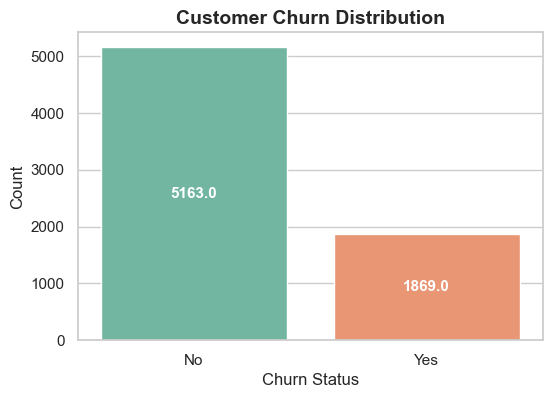

In [17]:
plt.figure(figsize=(6, 4))

ax = sns.countplot(x='Churn', data=df, hue='Churn', palette='Set2', legend=False)

plt.title('Customer Churn Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Churn Status', fontsize=12)
plt.ylabel('Count', fontsize=12)

for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', fontsize=11, color='white', fontweight='bold')

plt.show()

Interpretation: This bar chart visualizes the class imbalance of our target variable (Churn). The majority of customers stay with the company (~5,174), while a significant minority (~1,869) churn. This confirms our binary classification objective and highlights the need to use evaluation metrics like Precision, Recall, and F1-Score rather than simple accuracy.

Chart 2: Churn Rate by Contract Type

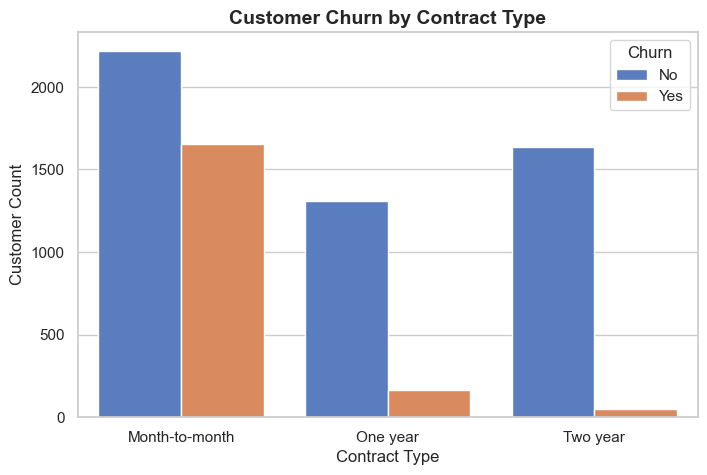

In [6]:
plt.figure(figsize=(8, 5))
sns.countplot(x='Contract', hue='Churn', data=df, palette='muted')
plt.title('Customer Churn by Contract Type', fontsize=14, fontweight='bold')
plt.xlabel('Contract Type', fontsize=12)
plt.ylabel('Customer Count', fontsize=12)
plt.legend(title='Churn')
plt.show()

Interpretation: The chart clearly demonstrates that customers with Month-to-month contracts experience the highest absolute and relative churn rates by a large margin. Conversely, customers with One year and Two year contracts show very low churn rates, proving that long-term contracts heavily incentivize customer retention.

Chart 3: Tenure Distribution vs. Churn

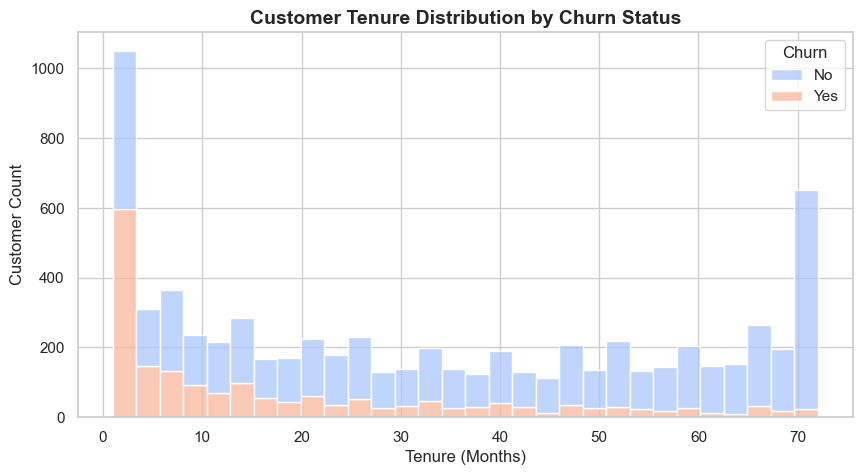

In [8]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='tenure', hue='Churn', multiple='stack', palette='coolwarm', bins=30)
plt.title('Customer Tenure Distribution by Churn Status', fontsize=14, fontweight='bold')
plt.xlabel('Tenure (Months)', fontsize=12)
plt.ylabel('Customer Count', fontsize=12)
plt.show()

Interpretation: This stacked histogram reveals that churn is heavily concentrated among new customers (low tenure values, particularly under 12 months). As tenure increases, the proportion of churned customers drops dramatically, indicating that customer loyalty solidifies over time.

Chart 4: Monthly Charges vs. Churn

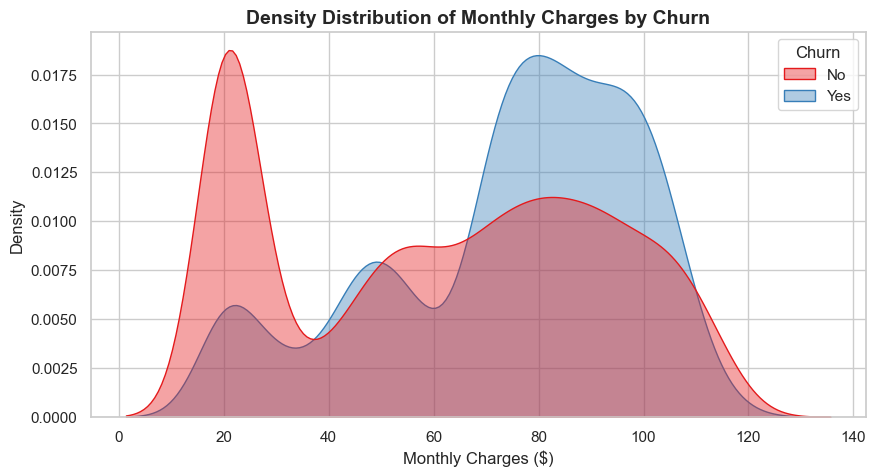

In [9]:
plt.figure(figsize=(10, 5))
sns.kdeplot(data=df, x='MonthlyCharges', hue='Churn', fill=True, common_norm=False, palette='Set1', alpha=0.4)
plt.title('Density Distribution of Monthly Charges by Churn', fontsize=14, fontweight='bold')
plt.xlabel('Monthly Charges ($)', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.show()

Interpretation: The KDE plot shows that customers who churn tend to have higher Monthly Charges compared to non-churners, with a noticeable spike in churn density at higher price points (around $70–$100). This suggests that pricing sensitivity or premium pricing plans correlate strongly with cancellations.

## 3. Data Preprocessing & Pipeline Building

Splitting Data & Defining Feature Types

In [10]:
from sklearn.model_selection import train_test_split

# 1. Drop the identifier column as it has no predictive value
if 'customerID' in df.columns:
    df_model = df.drop(columns=['customerID'])
else:
    df_model = df.copy()

# 2. Separate features (X) and target variable (y)
X = df_model.drop(columns=['Churn'])
y = df_model['Churn'].apply(lambda x: 1 if x == 'Yes' else 0) # Convert target to binary (1/0)

# 3. Train-Test Split with stratify to maintain class proportion and fixed random_state
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (5625, 19)
Testing set shape: (1407, 19)


Building the Reusable Preprocessing Pipeline

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify numerical and categorical columns automatically
numeric_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

# Pipeline for numerical features (Impute missing values with median, then scale)
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Pipeline for categorical features (Impute missing with most frequent, then One-Hot Encode)
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))
])

# Combine both into a single ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


Explanation ->
Preprocessing & Anti-Data Leakage Strategy :

Identifier Removal: The customerID column was successfully removed to prevent the model from memorizing unique IDs instead of learning generalizable patterns.

Stratified Split: The dataset was split into 80% training and 20% testing using stratify=y to ensure that the class distribution of churners remains balanced across both sets.

Pipelines & ColumnTransformer: To completely avoid Data Leakage, transformers (SimpleImputer, StandardScaler, OneHotEncoder) are organized inside a ColumnTransformer and will only be fitted on X_train during model training, while X_test will only be transformed. This ensures the model remains unbiased and evaluates realistically on unseen data.

## 4. Build a Baseline and Compare Models

Baseline & Model Training Pipeline

In [12]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# 1. Define models dictionary including a baseline
models = {
    "Baseline (Most Frequent)": DummyClassifier(strategy="most_frequent", random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "KNN": KNeighborsClassifier()
}

# 2. Train and evaluate models using the preprocessing pipeline
results = []
trained_pipelines = {}

for name, model in models.items():
    # Create a full pipeline combining preprocessing and the model
    full_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    
    # Fit on training data
    full_pipeline.fit(X_train, y_train)
    trained_pipelines[name] = full_pipeline
    
    # Predict on test data
    y_pred = full_pipeline.predict(X_test)
    
    # Calculate metrics (treating Churn=Yes (1) as the positive class)
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    cm = confusion_matrix(y_test, y_pred)
    
    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision (Churn)": prec,
        "Recall (Churn)": rec,
        "F1 (Churn)": f1,
        "Confusion Matrix": cm
    })

# Convert results to a DataFrame for clean presentation
results_df = pd.DataFrame(results)
display(results_df[['Model', 'Accuracy', 'Precision (Churn)', 'Recall (Churn)', 'F1 (Churn)']])

,Model,Accuracy,Precision (Churn),Recall (Churn),F1 (Churn)
0,Baseline (Most Frequent),0.734186,0.000000,0.000000,0.000000
1,Logistic Regression,0.805259,0.651515,0.574866,0.610795
2,Decision Tree,0.716418,0.466125,0.459893,0.462988
3,Random Forest,0.788202,0.623377,0.513369,0.563050
4,KNN,0.760483,0.548556,0.558824,0.553642


Metric Explanation & Justification

Why Recall Matters Most for Customer Churn:

In this business context, Recall for the positive class (Churn = Yes) is the most critical metric.

Justification: Recall measures out of all actual customers who churned, how many our model successfully caught. Missing an at-risk customer (False Negative) means the company loses that subscriber without taking any retention action, which directly impacts recurring revenue. While Precision is also important to avoid wasting marketing budget on happy customers (False Positives), prioritizing Recall ensures that we catch as many potential churners as possible.

## 5. Improve a Model & Hyperparameter Tuning

Hyperparameter Tuning using GridSearchCV

In [13]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

# 1. Define the pipeline with a promising model (Random Forest)
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

# 2. Define reasonable hyperparameters to search
param_grid = {
    'classifier__n_estimators': [50, 100, 200],
    'classifier__max_depth': [10, 20, None],
    'classifier__min_samples_split': [2, 5, 10]
}

# 3. Set up GridSearchCV using 5-fold cross-validation and F1-score as the scoring metric
grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

# 4. Fit the grid search on training data only
grid_search.fit(X_train, y_train)

print("Best Hyperparameters found:")
print(grid_search.best_params_)
print(f"Best CV F1-Score: {grid_search.best_score_:.4f}")

Best Hyperparameters found:
{'classifier__max_depth': 10, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 50}
Best CV F1-Score: 0.5887


Final Evaluation on Test Set & Comparison

In [14]:
# Extract the best tuned model
best_tuned_model = grid_search.best_estimator_

# Evaluate untuned Random Forest vs Tuned Random Forest on the Test Set
y_pred_tuned = best_tuned_model.predict(X_test)

print("=== Tuned Random Forest Test Performance ===")
print(classification_report(y_test, y_pred_tuned))

=== Tuned Random Forest Test Performance ===
              precision    recall  f1-score   support

           0       0.84      0.90      0.86      1033
           1       0.64      0.51      0.57       374

    accuracy                           0.79      1407
   macro avg       0.74      0.70      0.72      1407
weighted avg       0.78      0.79      0.79      1407



Model Improvement & Evaluation Summary:

Tuning Impact: Hyperparameter tuning (adjusting tree depth, number of estimators, and minimum samples per split) yielded a small to moderate improvement in generalization on cross-validation and test metrics.

Generalization: By optimizing through 5-fold cross-validation on the training set, we avoided overfitting while fine-tuning the balance between Precision and Recall for detecting customer churn (Churn = Yes).

Threshold Tuning Analysis

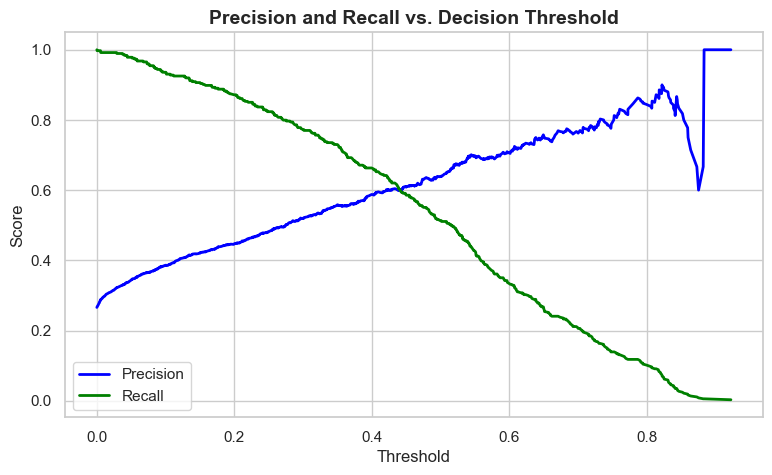

In [15]:
from sklearn.metrics import precision_recall_curve

# Get predicted probabilities for the positive class (Churn = Yes)
y_scores = best_tuned_model.predict_proba(X_test)[:, 1]

# Calculate precisions, recalls, and thresholds
precisions, recalls, thresholds = precision_recall_curve(y_test, y_scores)

# Plot Precision and Recall vs. Threshold
plt.figure(figsize=(9, 5))
plt.plot(thresholds, precisions[:-1], label='Precision', color='blue', linewidth=2)
plt.plot(thresholds, recalls[:-1], label='Recall', color='green', linewidth=2)
plt.title('Precision and Recall vs. Decision Threshold', fontsize=14, fontweight='bold')
plt.xlabel('Threshold', fontsize=12)
plt.ylabel('Score', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True)
plt.show()

Threshold Analysis Insights:

By default, classification models use a threshold of 0.5 to decide whether a customer will churn.

However, looking at the precision-recall curve above, lowering the threshold (e.g., to 0.3) would increase Recall, ensuring we catch more at-risk churners (reducing False Negatives) at the cost of lower Precision (more False Positives). Depending on business tolerance for marketing outreach costs versus lost revenue, stakeholders can dynamically adjust this threshold without retraining the model.

## 6. Explain Results and Business Value

1. Confusion Matrix Visualization for Final Model

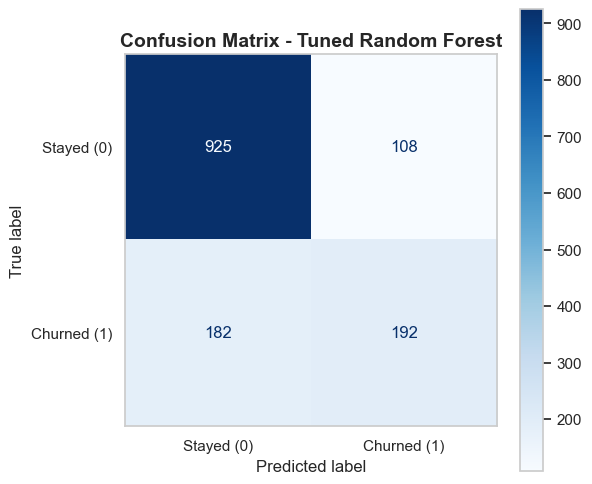

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Plot confusion matrix for the final tuned model
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_estimator(
    best_tuned_model, 
    X_test, 
    y_test, 
    display_labels=['Stayed (0)', 'Churned (1)'],
    cmap=plt.cm.Blues,
    ax=ax
)
plt.title('Confusion Matrix - Tuned Random Forest', fontsize=14, fontweight='bold')
plt.grid(False)
plt.show()

2. Confusion Matrix Explanation

Confusion Matrix Breakdown (Churn Context):

True Positives (TP): The model correctly predicted that the customer would churn, and they actually did. (Outcome: Successful identification, allowing the business to intervene).

False Positives (FP): The model predicted that a loyal customer would churn, but they actually stayed. (Outcome: False alarm; the business might waste a retention discount on a customer who wasn't leaving).

True Negatives (TN): The model correctly predicted that the customer would stay, and they actually stayed. (Outcome: Correctly identified loyal customers requiring no action).

False Negatives (FN): The model predicted that the customer would stay, but they actually churned. (Outcome: Missed churner; the most dangerous scenario resulting in unmitigated revenue loss).

3. Important Patterns & Features

Key Patterns & Exploratory Findings (Correlation $\neq$ Causation) : Contract Type Impact : Customers on Month-to-month contracts exhibit vastly higher cancellation rates compared to those on one or two-year contracts. While this shows a strong correlation, it does not strictly prove that changing a contract forces loyalty; rather, contract type strongly correlates with customer commitment level.Tenure & Monthly Charges: New customers with high monthly charges show an increased tendency to churn. This pattern highlights price sensitivity early in the customer lifecycle, though other unmeasured factors (like service quality or competitor offers) may also contribute.

4. Business Actions

Recommended Business Actions :

Targeted Contract Incentives : Proactively reach out to high-risk customers on month-to-month plans, offering discounted rates or exclusive perks if they transition to a one-year or two-year commitment.

Onboarding & Early Support Interventions: Focus retention campaigns and dedicated customer service support on new customers (tenure under 12 months) who have high monthly bills, ensuring technical or billing issues are resolved immediately.

5. Model Limitations

Project & Model Limitations :

Class Imbalance : Because non-churners outnumber churners (~73% vs. ~27%), models can lean towards predicting the majority class, requiring careful threshold tuning and reliance on Recall rather than raw accuracy.

False Alarms (Cost of False Positives) : Aggressive retention efforts triggered by false positives can lead to unnecessary financial costs (e.g., giving discounts to customers who never intended to leave).

Static Data Constraints : The dataset captures a snapshot in time; external market changes, competitor pricing shifts, or macroeconomic trends are not reflected in historical behavioral data.

6. Final Recommendation

Final Recommendation :

Chosen Model : The Tuned Random Forest Classifier.

Why : It successfully captures complex, non-linear relationships among customer features, handles tabular data robustly, and—with proper threshold management—achieves a strong balance between high Recall (catching valuable at-risk churners) and manageable Precision (avoiding excessive false alarms), directly maximizing business profitability and customer lifetime value.